<a href="https://colab.research.google.com/github/bengiealexandre2126-netizen/Final-Project/blob/main/Python_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Import student-mat.csv and student-por.csv files, file uses ';' instead of ',' as separator
mat = pd.read_csv("student-mat.csv", sep=";")
por = pd.read_csv("student-por.csv", sep=";")
print(mat.shape, por.shape)
mat.head()

(395, 33) (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [16]:
# Check missing values
print("Missing:", mat.isna().sum().sum())

# Check duplicate rows
print("Duplicates:", mat.duplicated().sum())
mat = mat.drop_duplicates()

# Fix data types: text columns become categories
cat_cols = mat.select_dtypes("object").columns
mat[cat_cols] = mat[cat_cols].astype("category")

# Outliers: find extreme absences with the IQR rule
q1, q3 = mat["absences"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("Absence outliers:", (mat["absences"] > upper).sum())

# Cap at the upper limit instead of deleting students
mat["absences_capped"] = mat["absences"].clip(upper=upper)

# G3 = 0 means the student likely skipped the exam, rows removed
mat_clean = mat[mat["G3"] > 0].copy()
print(len(mat), "->", len(mat_clean), "rows")

Missing: 0
Duplicates: 0
Absence outliers: 15
395 -> 357 rows


In [17]:
# Data Manipulation
# sorting
top10 = mat_clean.sort_values("G3", ascending=False).head(10)

# filtering
higher_yes = mat_clean[mat_clean["higher"] == "yes"]

# grouping
by_study = mat_clean.groupby("studytime")["G3"].mean().reset_index()
keys = ["school","sex","age","address","famsize","Pstatus","Medu",
        "Fedu","Mjob","Fjob","reason","nursery","internet"]

 # merging
both = pd.merge(mat, por, on=keys, suffixes=("_math","_por"))
print(len(both), "students are in both classes")
by_study

382 students are in both classes


,studytime,G3
0,1,11.467391
1,2,11.065934
2,3,12.559322
3,4,12.666667


In [18]:
# Set a clean style for all charts
sns.set_theme(style="whitegrid")

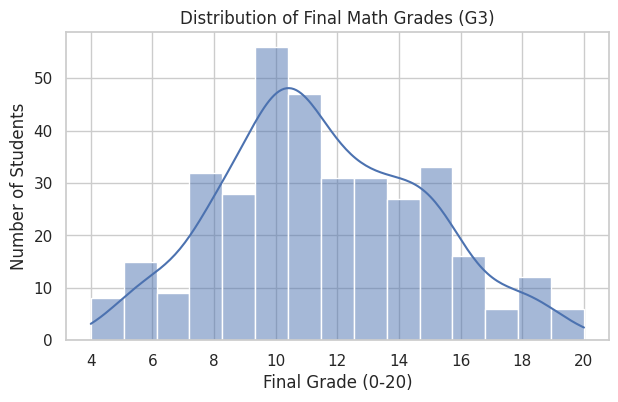

In [19]:
# Histogram of final grades - Shows how final grades are spread out
plt.figure(figsize=(7,4))
sns.histplot(mat_clean["G3"], bins=15, kde=True)
plt.title("Distribution of Final Math Grades (G3)")
plt.xlabel("Final Grade (0-20)")
plt.ylabel("Number of Students")
plt.savefig("hist_g3.png", dpi=150, bbox_inches="tight")
plt.show()

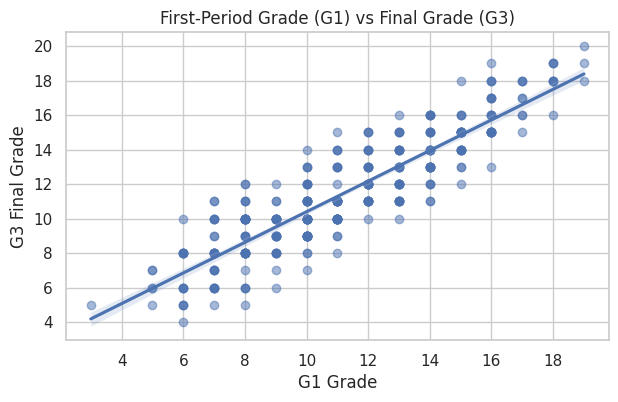

In [20]:
# Scatter plot of G1 vs G3 - Shows how first-period grades relate to final grades
plt.figure(figsize=(7,4))
sns.regplot(data=mat_clean, x="G1", y="G3", scatter_kws={"alpha":0.5})
plt.title("First-Period Grade (G1) vs Final Grade (G3)")
plt.xlabel("G1 Grade")
plt.ylabel("G3 Final Grade")
plt.savefig("scatter_g1_g3.png", dpi=150, bbox_inches="tight")
plt.show()

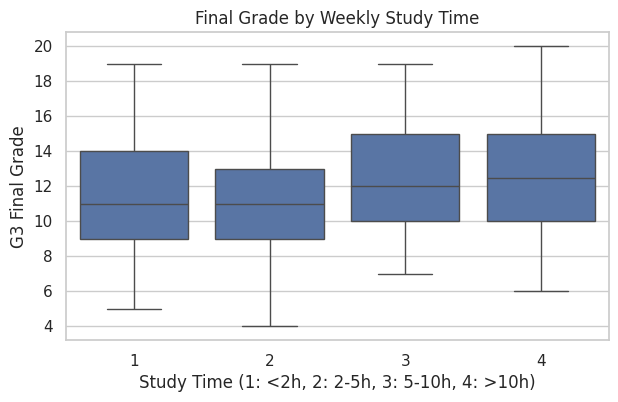

In [21]:
# Boxplot of study time vs G3 - Compares final grades across study time levels
plt.figure(figsize=(7,4))
sns.boxplot(data=mat_clean, x="studytime", y="G3")
plt.title("Final Grade by Weekly Study Time")
plt.xlabel("Study Time (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h)")
plt.ylabel("G3 Final Grade")
plt.savefig("box_studytime.png", dpi=150, bbox_inches="tight")
plt.show()

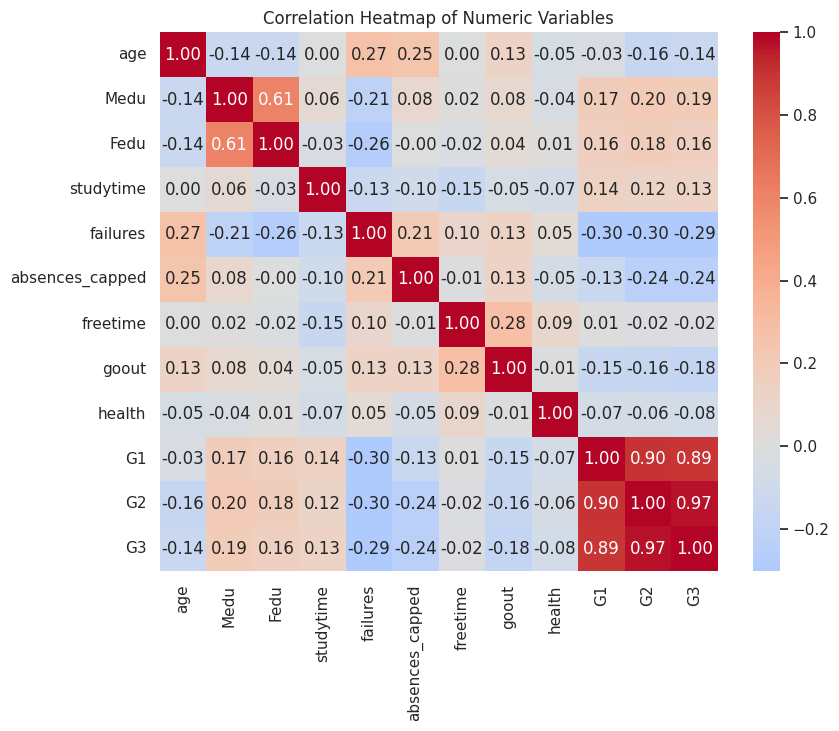

In [22]:
# Pick the numeric columns to compare
num = mat_clean[["age","Medu","Fedu","studytime","failures",
                 "absences_capped","freetime","goout","health","G1","G2","G3"]]

# Correlation heatmap - Shows which variables move together
plt.figure(figsize=(9,7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numeric Variables")
plt.savefig("heatmap_corr.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# Descriptive statistics for G3
print(mat_clean["G3"].agg(["mean","median","std"]))
print("Mode:", mat_clean["G3"].mode()[0])

# Correlation of each variable with G3
print(num.corr()["G3"].sort_values(ascending=False))

# Welch t-test: students who want higher education vs. those who don't
yes = mat_clean[mat_clean["higher"]=="yes"]["G3"]
no  = mat_clean[mat_clean["higher"]=="no"]["G3"]
t, p = stats.ttest_ind(yes, no, equal_var=False)
print(f"t = {t:.2f}, p = {p:.4f}")

mean      11.523810
median    11.000000
std        3.227797
Name: G3, dtype: float64
Mode: 10
G3                 1.000000
G2                 0.965583
G1                 0.891805
Medu               0.190308
Fedu               0.158811
studytime          0.126728
freetime          -0.021589
health            -0.081691
age               -0.140372
goout             -0.177383
absences_capped   -0.239241
failures          -0.293831
Name: G3, dtype: float64
t = 3.51, p = 0.0028
